In [194]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import python_anesthesia_simulator as pas
from scipy import signal, stats


In [195]:
def plot_bode_gain(signal_data, sample_time=1.0):
    """
    Plot the Bode magnitude (gain) of a sampled signal.
    
    Parameters
    ----------
    signal_data : array_like
        The time-domain signal samples.
    sample_time : float
        Sampling interval in seconds (default = 1.0).
    """

    # Compute frequency response using FFT
    n = len(signal_data)
    fs = 1.0 / sample_time  # sampling frequency [Hz]
    freq = np.fft.rfftfreq(n, d=sample_time)
    fft_vals = np.fft.rfft(signal_data)
    
    # Magnitude in dB
    magnitude_db = 20 * np.log10(np.abs(fft_vals) / np.max(np.abs(fft_vals)))
    
    # Plot
    plt.semilogx(freq, magnitude_db)
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Gain [dB]")
    plt.grid(True, which='both')
    return freq

def compare_bode_signal_and_system(signal_data, sys, sample_time=1.0):
    """
    Compare Bode gain of a discrete-time system and a measured signal on the same frequency axis.

    Parameters
    ----------
    signal_data : array_like
        Measured discrete-time signal.
    num, den : array_like
        Discrete-time transfer function coefficients (numerator and denominator).
    sample_time : float
        Sampling interval in seconds.
    """

    n = len(signal_data)
    fs = 1.0 / sample_time

    # === System Bode response ===
    w = np.logspace(-2.5, 0.5)
    w, mag_sys, phase_sys = signal.bode(sys, w)  # w in rad/s

    # Convert system frequency vector (rad/s) to Hz
    f_sys = w / (2 * np.pi)

    # === Signal FFT ===
    freq_signal = np.fft.rfftfreq(n, d=sample_time)
    fft_vals = np.fft.rfft(signal_data)
    mag_abs = np.abs(fft_vals)

    mag_db = 20 * np.log10(mag_abs / np.sort(mag_abs)[::-1][2])

    # interpolate to system frequencies
    # mag_signal_interp = np.interp(f_sys, freq_signal, mag_db, left=np.nan, right=np.nan)

    # === Plot ===
    plt.figure(figsize=(8, 5))
    plt.semilogx(freq_signal, mag_db, '--', label="Measured Signal FFT Gain", lw=1.5)
    plt.semilogx(f_sys, mag_sys, label="System Bode Gain", lw=2)
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Gain [dB]")
    plt.title("Bode Gain: System vs Measured Signal")
    plt.grid(True, which='both', ls='--')
    plt.legend()
    plt.tight_layout()
    plt.show()

In [196]:
data_raw = pd.read_csv('data/database.csv')

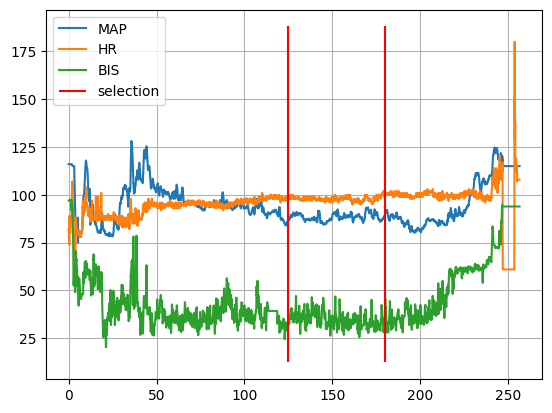

In [224]:
caseid = data_raw.caseid.unique()[35]
data_case = data_raw.query('caseid==@caseid')
steady_time_start = 125*60
steady_time_end = 180*60
for signal_name in ['MAP', 'HR', 'BIS']:
    plt.plot(data_case.Time/60, data_case[signal_name], label=signal_name)

ylim = plt.gca().get_ylim()
plt.vlines([steady_time_start/60, steady_time_end/60], ylim[0], ylim[1], 'r', label='selection')
plt.grid()
plt.legend()
plt.show()

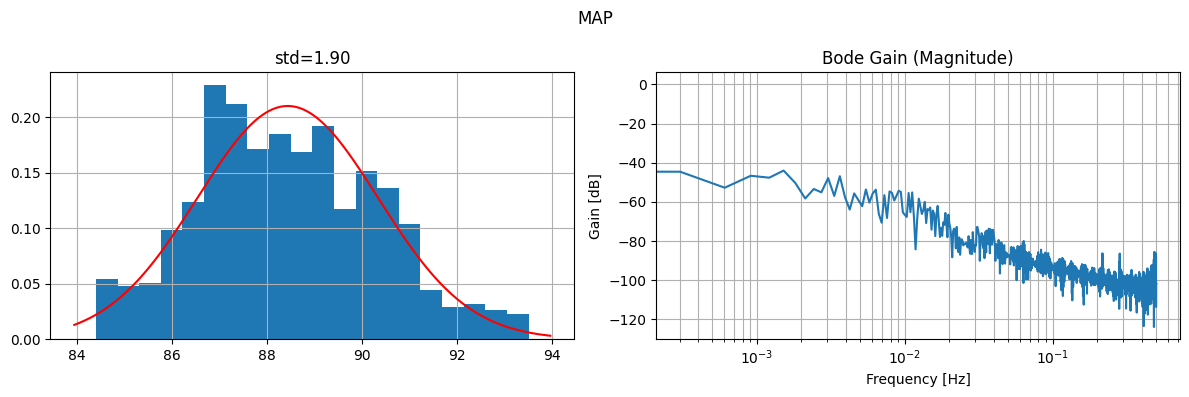

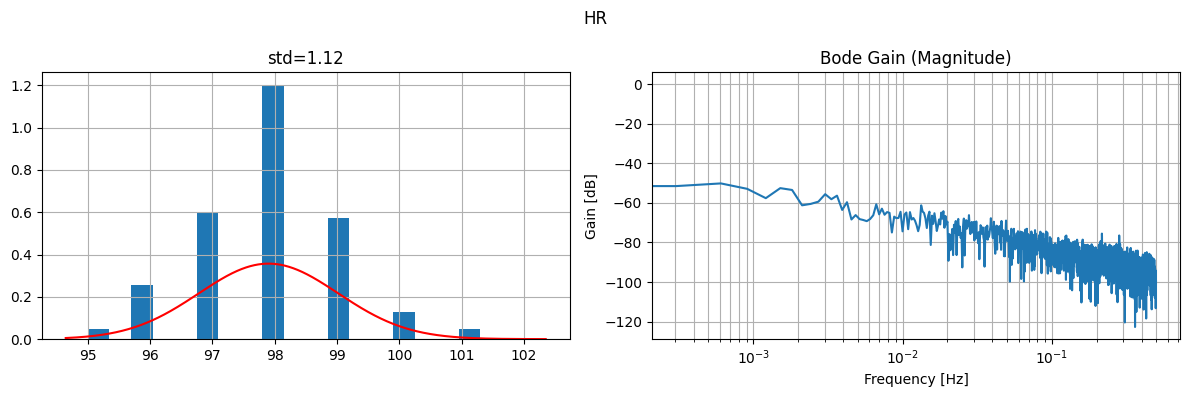

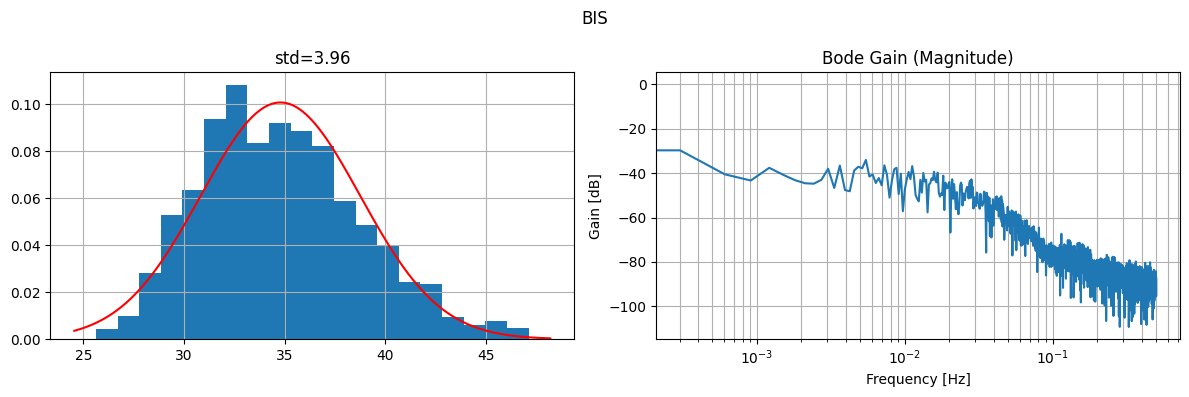

In [ ]:


steady_period = data_case.query('(Time >= @steady_time_start) & (Time <= @steady_time_end)')

for signal_name in ['MAP', 'HR', 'BIS']:
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.hist(steady_period[signal_name].values, bins=20, density=True)
    mu = steady_period[signal_name].mean()
    std = steady_period[signal_name].std()
    xlim = plt.gca().get_xlim()
    x = np.arange(xlim[0], xlim[1], 0.001)
    y = stats.norm.pdf(x, mu, std)
    plt.plot(x, y, 'r')
    plt.title(f'std={std:.2f}')
    plt.grid()
    plt.subplot(1,2,2)
    plot_bode_gain(steady_period[signal_name].values)
    plt.title("Bode Gain (Magnitude)")
    plt.suptitle(signal_name)
    plt.tight_layout()
    plt.show()

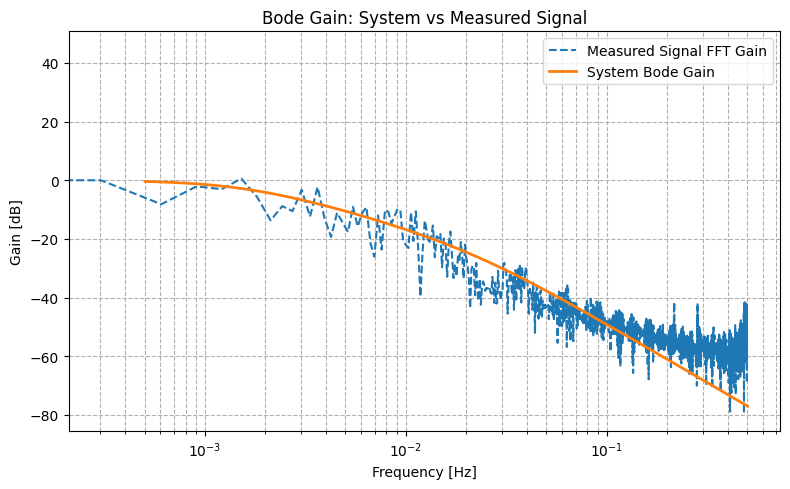

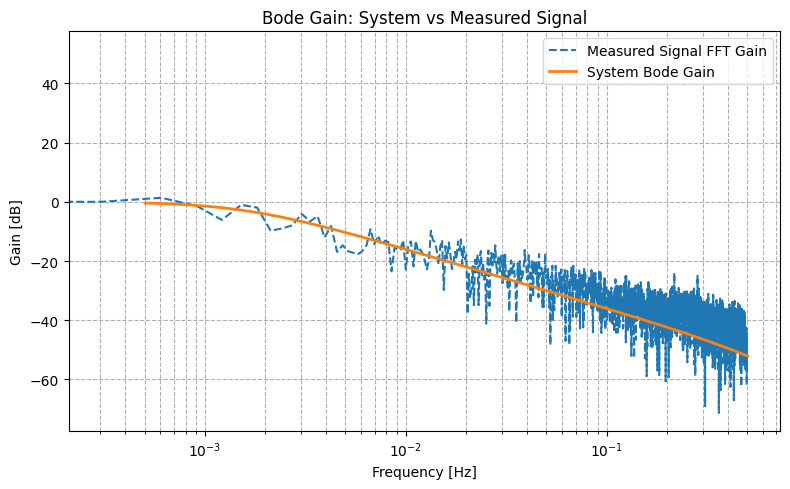

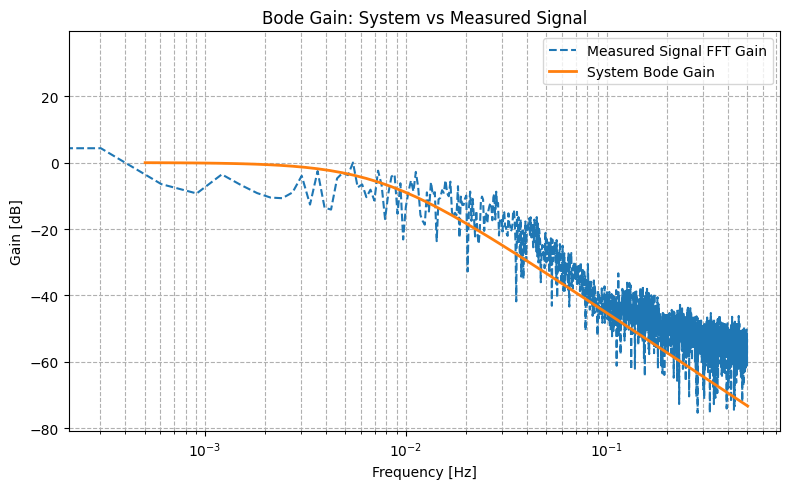

In [199]:
bis_noise_std = 3
hr_noise_std = 1.75
map_noise_std = 2.5

# MAP
xi = 2
a = 4 * xi**2 - 2
y = (-a + np.sqrt(a**2 + 4)) / 2
omega = 0.01/np.sqrt(y)
map_filter = signal.TransferFunction([1], [1 / omega**2, 2 * xi / omega, 1])
# HR
xi = 10
a = 4 * xi**2 - 2
y = (-a + np.sqrt(a**2 + 4)) / 2
omega = 0.01/np.sqrt(y)
hr_filter = signal.TransferFunction([1], [1 / omega**2, 2 * xi / omega, 1])
# bis
xi = 1
a = 4 * xi**2 - 2
y = (-a + np.sqrt(a**2 + 4)) / 2
omega = 0.03/np.sqrt(y)
bis_filter = signal.TransferFunction([1], [1 / omega**2, 2 * xi / omega, 1])

filters = [map_filter, hr_filter, bis_filter]

for i, signal_name in enumerate(['MAP', 'HR', 'BIS']):
    compare_bode_signal_and_system(steady_period[signal_name].values, filters[i])


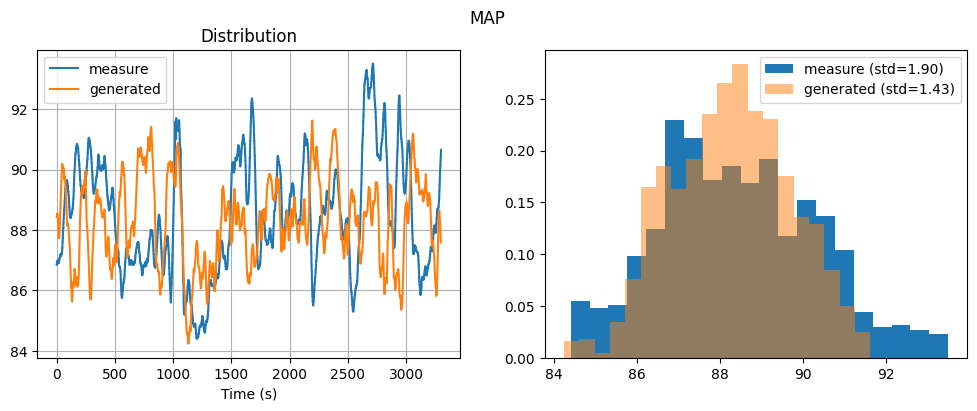

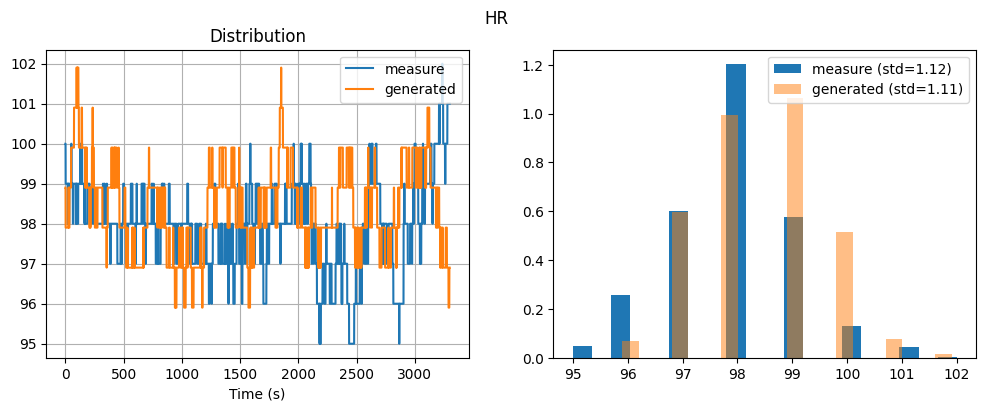

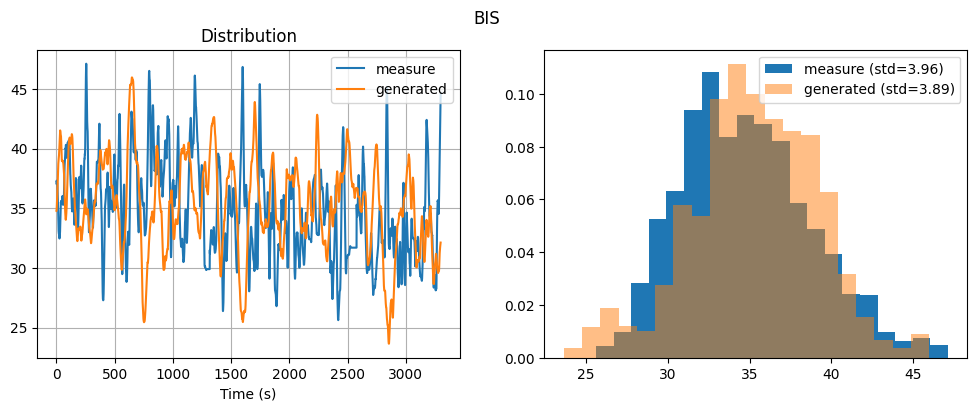

In [221]:
map_noise_std = 30
hr_noise_std = 17
bis_noise_std = 35
# simulate noise
length = steady_time_end - steady_time_start
white_noise = np.random.normal(0, map_noise_std, length)
noise_filter_map = map_filter.to_discrete(1, method='bilinear')
_, map_noise = signal.dlsim(noise_filter_map, u=white_noise)

white_noise = np.random.normal(0, hr_noise_std, length)
noise_filter_hr = hr_filter.to_discrete(1, method='bilinear')
_, hr_noise = signal.dlsim(noise_filter_hr, u=white_noise)
hr_noise = np.ceil(hr_noise)

white_noise = np.random.normal(0, bis_noise_std, length)
noise_filter_bis = bis_filter.to_discrete(1, method='bilinear')
_, bis_noise = signal.dlsim(noise_filter_bis, u=white_noise)

noises = [map_noise, hr_noise, bis_noise]
for i, signal_name in enumerate(['MAP', 'HR', 'BIS']):
    std_signal = np.std(steady_period[signal_name].values)
    std_noise = np.std(noises[i])
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(steady_period[signal_name].values, label='measure')
    plt.plot(noises[i]+steady_period[signal_name].mean(), label='generated')
    plt.title('Time plot')
    plt.xlabel('Time (s)')
    plt.legend()
    plt.grid()
    plt.suptitle(signal_name)
    plt.title('Distribution')
    plt.subplot(1,2,2)
    plt.hist(steady_period[signal_name].values, density=True, label=f'measure (std={std_signal:.2f})', bins = 20)
    plt.hist(noises[i]+steady_period[signal_name].mean(), alpha=0.5, density=True, label=f'generated (std={std_noise:.2f})', bins = 20)
    plt.legend()
    plt.show()